In [1]:
# Reinforcement Learning is a type of machine learning in which an agent learns by interacting with an environment and receiving rewards or penalties for its actions. 
# The main objective is to learn the best actions that maximize the total reward over time. 
# It is based on trial and error, where the agent improves its decisions through repeated experience.

# Q-Learning is a popular model-free, off-policy Reinforcement Learning algorithm used to find the optimal action for each state. 
# It uses a Q-table to store the expected rewards for taking different actions in different states. 
# Initially, all Q-values are set to zero and are updated as the agent interacts with the environment.

# The algorithm uses an Epsilon-Greedy Strategy to balance exploration and exploitation. 
# Exploration means trying new actions, while exploitation means selecting the best-known action. 
# The Q-values are updated using the Bellman equation, which considers the immediate reward and the maximum expected future reward.

# Q-Learning is widely used in robotics, game playing, navigation and decision-making systems. 
# Its main advantages are that it does not require a predefined environment model and learns through experience. 
# However, it may require many training episodes to learn an optimal policy.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
q = np.zeros((16, 4))
alpha, gamma, epsilon = 0.8, 0.95, 1.0

In [3]:
# Find next state
def next_state(s, a):
    r, c = divmod(s, 4)
    dr, dc = [(-1,0), (1,0), (0,-1), (0,1)][a]
    r, c = r + dr, c + dc
    return (r*4+c) if 0 <= r < 4 and 0 <= c < 4 else s

In [4]:
# Training
for _ in range(1000):
    s = 0
    for _ in range(50):
        a = np.random.randint(4) if np.random.rand() < epsilon else np.argmax(q[s])
        ns = next_state(s, a)
        reward = 10 if ns == 15 else (-2 if ns == s else -1)
        q[s,a] += alpha * (reward + gamma*np.max(q[ns]) - q[s,a])
        s = ns
        if s == 15: break
    epsilon = max(0.05, epsilon * 0.995)

In [5]:
# Display Q-table
print("Q-Table:\n", np.round(q, 2))

Q-Table:
 [[ 1.05  3.21  1.05  3.21]
 [ 2.21  4.44  2.05  4.44]
 [ 3.44  5.72  3.21  5.72]
 [ 4.72  7.07  4.44  4.72]
 [ 2.05  4.44  2.21  4.44]
 [ 3.21  5.72  3.21  5.72]
 [ 4.44  7.07  4.44  7.07]
 [ 5.72  8.5   5.72  6.07]
 [ 3.21  5.72  3.44  5.72]
 [ 4.44  7.07  4.44  7.07]
 [ 5.72  8.5   5.72  8.5 ]
 [ 7.07 10.    7.07  7.5 ]
 [ 4.44  4.72  4.72  7.07]
 [ 5.72  6.07  5.72  8.5 ]
 [ 7.07  7.5   7.07 10.  ]
 [ 0.    0.    0.    0.  ]]


In [6]:
# Test learned path
s, path = 0, [0]
for _ in range(50):
    s = next_state(s, np.argmax(q[s]))
    path.append(s)
    if s == 15: break
print("Path:", path)
print("Goal Reached:", s == 15)

Path: [0, 4, 8, 12, 13, 14, 15]
Goal Reached: True


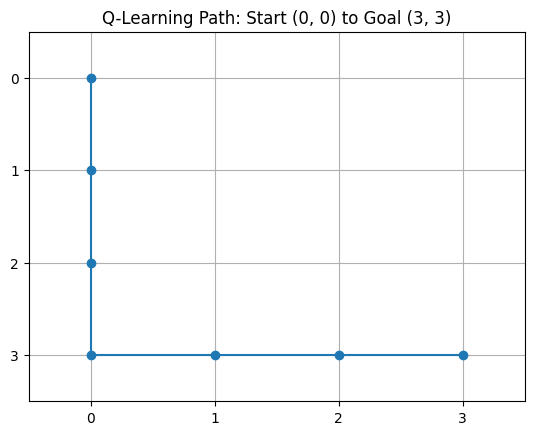

In [7]:
# Visualize the learned path
rows, columns = np.divmod(path, 4)
plt.plot(columns, rows, marker="o")
plt.xticks(range(4))
plt.yticks(range(4))
plt.xlim(-0.5, 3.5)
plt.ylim(3.5, -0.5)
plt.grid()
plt.title("Q-Learning Path: Start (0, 0) to Goal (3, 3)")
plt.show()